# 02 · EDA of the credit history tables

**Goal:** understand what the two history tables tell us about an applicant, check that nothing in them comes from after the application, and compare the training population with the Kaggle test population.

| Table | One row is | Keys |
|---|---|---|
| `application_train` | one loan application | `SK_ID_CURR` |
| `bureau` | one credit the applicant holds or held **at other institutions**, reported by the Credit Bureau | `SK_ID_BUREAU`, linked by `SK_ID_CURR` |
| `installments_payments` | one instalment of a **previous Home Credit loan**, with what was due and what was paid | `SK_ID_PREV` + instalment number, linked by `SK_ID_CURR` |

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from credit_risk.config import project_path
from credit_risk.data import load_table

FIGURES = project_path("figures")
sns.set_theme(style="whitegrid")

app = load_table("application_train")
test = load_table("application_test")
bureau = load_table("bureau")
inst = load_table("installments_payments")
target = app[["SK_ID_CURR", "TARGET"]]
print(app.shape, test.shape, bureau.shape, inst.shape)

(307511, 122) (48744, 121) (1716428, 17) (13605401, 8)


**Result:** `(307511, 122) (48744, 121) (1716428, 17) (13605401, 8)`. `application_test` has no `TARGET`: it cannot measure a model, only describe a population.

## 1. Relational structure

In [21]:
# Is SK_ID_BUREAU a unique key of bureau? (one row per external credit)
print("SK_ID_BUREAU unique:", bureau["SK_ID_BUREAU"].nunique() == bureau.shape[0])

# Number of rows per applicant in each history table (groupby + size).
bureau_per_app = bureau.groupby("SK_ID_CURR").size()
inst_per_app = inst.groupby("SK_ID_CURR").size()
pd.DataFrame({"bureau": bureau_per_app.describe(), "installments": inst_per_app.describe()}).round(1)

SK_ID_BUREAU unique: True


,bureau,installments
count,305811.0,339587.0
mean,5.6,40.1
std,4.4,41.1
min,1.0,1.0
25%,2.0,12.0
50%,4.0,25.0
75%,8.0,51.0
max,116.0,372.0


**Result:** `SK_ID_BUREAU` is unique. Median 4 bureau credits per applicant (max 116), median 25 instalments (max 372).

**Finding:** both tables are **one-to-many**: one applicant has several rows.
**Decision:** never join them directly onto the application table. Aggregate per `SK_ID_CURR` first (count, mean, max), then left-join one row per applicant. A direct join would multiply the application rows and inflate every sum and every default rate.

**Question:** how many applicants have **no** history at all, and are they riskier?

In [22]:
# Boolean Series on `target`: does the applicant appear in bureau? in installments?
has_bureau = target["SK_ID_CURR"].isin(bureau["SK_ID_CURR"])
has_inst = target["SK_ID_CURR"].isin(inst["SK_ID_CURR"])

coverage = pd.DataFrame({
    "with history": [has_bureau.mean(), has_inst.mean()],
    "default rate with": [target.loc[has_bureau, "TARGET"].mean(), target.loc[has_inst, "TARGET"].mean()],
    # Default rate of the applicants WITHOUT history (use ~).
    "default rate without": [target.loc[~has_bureau, "TARGET"].mean(), target.loc[~has_inst, "TARGET"].mean()],
    "n without": [(~has_bureau).sum(), (~has_inst).sum()],
}, index=["bureau", "installments"])
coverage.round(4)

,with history,default rate with,default rate without,n without
bureau,0.8569,0.0773,0.1012,44020
installments,0.9484,0.0819,0.0598,15868


**Result:** bureau: 85.69 % covered, default 7.73 % with history vs **10.12 %** without (44,020 applicants). Installments: 94.84 % covered, default 8.19 % with vs **5.98 %** without (15,868 applicants).

**Finding:** the two "no history" groups go in **opposite** directions:
- no Credit Bureau record (a "thin file": nobody can vouch for the client) means **more** risk;
- no previous Home Credit loan (a **new** customer) means **less** risk. Returning customers are a selected group: someone who comes back for another loan often still needs money.

**Decision:** after the left join, missing aggregates stay NaN (their own bin in the scorecard) and we add two flags `HAS_BUREAU` and `HAS_INSTALMENTS`. Never fill them with 0: "no credit" and "zero late payment" are not the same thing.

## 2. Leakage check: is everything dated before the application?

All `DAYS_*` columns are counted back from the application date: a value **above 0** is after the application, so it would not be known when the bank decides.

In [ ]:
day_cols = {
    "bureau": ["DAYS_CREDIT", "DAYS_CREDIT_ENDDATE", "DAYS_ENDDATE_FACT", "DAYS_CREDIT_UPDATE"],
    "installments": ["DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT"],
}
rows = []
for table, cols in day_cols.items():
    df = bureau if table == "bureau" else inst
    for col in cols:
        # Number of rows dated after the application (strictly positive days).
        n_after = (df[col] > 0).sum()
        rows.append({"table": table, "column": col, "rows after application": n_after, "max": df[col].max()})
pd.DataFrame(rows)

,table,column,rows after application,max
0,bureau,DAYS_CREDIT,0,0.0
1,bureau,DAYS_CREDIT_ENDDATE,602603,31199.0
2,bureau,DAYS_ENDDATE_FACT,0,0.0
3,bureau,DAYS_CREDIT_UPDATE,17,372.0
4,installments,DAYS_INSTALMENT,0,-1.0
5,installments,DAYS_ENTRY_PAYMENT,0,-1.0


**Result:** only two columns have positive values: `DAYS_CREDIT_ENDDATE` (602,603 rows, max 31,199) and `DAYS_CREDIT_UPDATE` (17 rows, max 372). Everything in `installments_payments` is before the application.

Read the column definitions before deciding:
- `DAYS_CREDIT_ENDDATE` is the **planned** end date of a credit. For an active credit it is naturally in the future, and the bank knows it on the application day (it is in the contract). **Not a leak.**
- `DAYS_CREDIT_UPDATE` is when the Credit Bureau last updated the record. On 17 rows the update happened **after** the application: the record may contain information the bank did not have.

**Finding:** the history is dated before the application, except 17 bureau records updated afterwards.
**Decision:** do not use `DAYS_CREDIT_UPDATE` as a feature. 17 rows is tiny, but the rule matters more than the size: a feature must be computable on the decision day.

In [ ]:
# Anomalies: end dates more than 40 years in the past (Home Credit's history covers about 8 years).
# Count the rows with DAYS_CREDIT_ENDDATE below -15,000 days.
print("DAYS_CREDIT_ENDDATE < -15000:", (bureau["DAYS_CREDIT_ENDDATE"] < -15000).sum())
print("oldest DAYS_CREDIT:", bureau["DAYS_CREDIT"].min(), "days, i.e.", round(bureau["DAYS_CREDIT"].min() / -365.25, 1), "years")

DAYS_CREDIT_ENDDATE < -15000: 146
oldest DAYS_CREDIT: -2922 days, i.e. 8.0 years


**Result:** 146 rows, while the oldest credit opened 2,922 days (8.0 years) ago.

**Finding:** a credit cannot end 40 years before it started: these are data-entry errors.
**Decision:** set end dates older than the credit itself to NaN when building features.

## 3. Payment behaviour signals

The strongest risk signal in banking is past behaviour. From the instalments:
- **days late** = `DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT` (positive means paid after the due date);
- **underpayment** = paid less than what was due (`AMT_PAYMENT < AMT_INSTALMENT`).

In [25]:
# Days late per instalment, floored at 0 (paying early is not "negative lateness").
inst["DAYS_LATE"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
inst["IS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] > inst["DAYS_INSTALMENT"]
# Underpaid instalment: paid strictly less than due.
inst["IS_UNDERPAID"] = inst["AMT_PAYMENT"] < inst["AMT_INSTALMENT"]

# One row per applicant: aggregate FIRST, then join.
# Named aggregation: share of late instalments, max days late, share underpaid.
inst_agg = inst.groupby("SK_ID_CURR").agg(
    LATE_SHARE=("IS_LATE", "mean"),
    MAX_DAYS_LATE=("DAYS_LATE", "max"),
    UNDERPAID_SHARE=("IS_UNDERPAID", "mean"),
)
behaviour = target.merge(inst_agg, on="SK_ID_CURR", how="left")
print("rows after the join:", len(behaviour))
inst_agg.describe().round(3)

rows after the join: 307511


,LATE_SHARE,MAX_DAYS_LATE,UNDERPAID_SHARE
count,339587.000,339578.000,339587.000
mean,0.074,17.844,0.083
std,0.114,108.275,0.148
min,0.000,0.000,0.000
25%,0.000,0.000,0.000
50%,0.018,1.000,0.000
75%,0.109,9.000,0.105
max,1.000,2884.000,1.000


**Result:** 307,511 rows after the join (the left join kept one row per application). Median late share 0.018, median max days late 1.0, median underpaid share 0.0.

In [26]:
bureau["IS_ACTIVE"] = bureau["CREDIT_ACTIVE"].eq("Active")
bureau["HAS_OVERDUE"] = bureau["AMT_CREDIT_SUM_OVERDUE"].fillna(0) > 0
# Per applicant: number of ACTIVE external credits, and whether ANY credit is overdue.
bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    N_ACTIVE=("IS_ACTIVE", 'sum'),
    ANY_OVERDUE=("HAS_OVERDUE", 'any'),
)
behaviour = behaviour.merge(bureau_agg, on="SK_ID_CURR", how="left")


def rate_by_band(df: pd.DataFrame, col: str, bins: list[float], labels: list[str]) -> pd.DataFrame:
    """Count and default rate per band of `col` (NaN rows, i.e. no history, are left out)."""
    bands = pd.cut(df[col], bins=bins, labels=labels)
    return df.groupby(bands, observed=True)["TARGET"].agg(count="size", default_rate="mean")


panels = {
    "Share of late instalments": rate_by_band(behaviour, "LATE_SHARE", [-0.001, 0, 0.05, 0.2, 1], ["0", "0-5 %", "5-20 %", "> 20 %"]),
    "Share of underpaid instalments": rate_by_band(behaviour, "UNDERPAID_SHARE", [-0.001, 0, 0.1, 1], ["0", "0-10 %", "> 10 %"]),
    "Active external credits": rate_by_band(behaviour, "N_ACTIVE", [-1, 0, 1, 2, 4, 100], ["0", "1", "2", "3-4", "5+"]),
    "Any overdue external credit": behaviour.groupby("ANY_OVERDUE")["TARGET"].agg(count="size", default_rate="mean"),
}
for name, table in panels.items():
    print(name); print(table.round(4), "\n")

Share of late instalments
             count  default_rate
LATE_SHARE                      
0           136644        0.0680
0-5 %        40212        0.0701
5-20 %       77325        0.0940
> 20 %       37462        0.1199 

Share of underpaid instalments
                  count  default_rate
UNDERPAID_SHARE                      
0                166497        0.0710
0-10 %            48984        0.0781
> 10 %            76162        0.1079 

Active external credits
          count  default_rate
N_ACTIVE                     
0         46341        0.0566
1         74103        0.0710
2         58383        0.0744
3-4       60052        0.0862
5+        24612        0.1205 

Any overdue external credit
              count  default_rate
ANY_OVERDUE                      
False        260157        0.0762
True           3334        0.1620 



**Result:** late share 0 → 6.80 %, above 20 % → 11.99 %. Underpaid share above 10 % → 10.79 % (vs 7.10 % for none). 5+ active credits → 12.05 % (vs 5.66 % for none). Any overdue external credit → **16.20 %** on 3,334 applicants (vs 7.62 %).

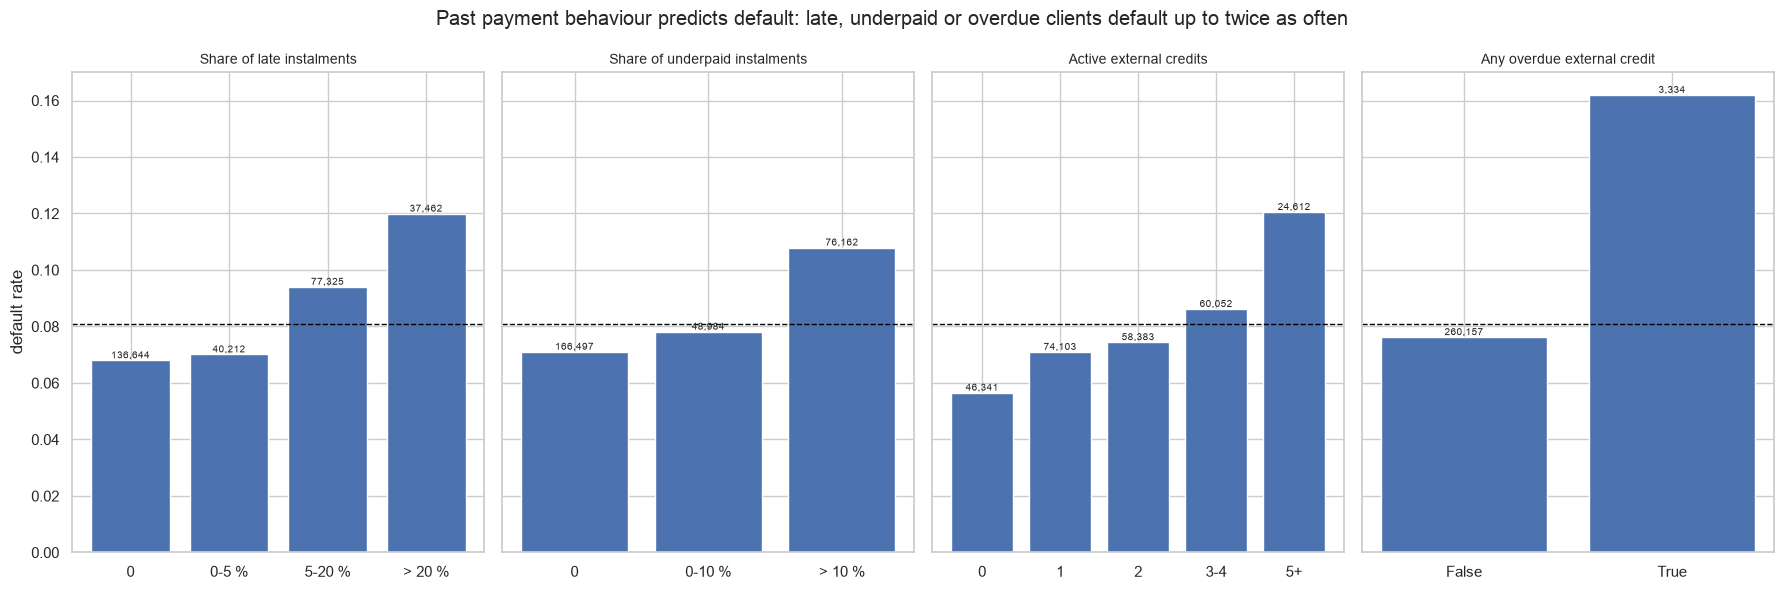

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
for ax, (name, table) in zip(axes, panels.items()):
    ax.bar(range(len(table)), table["default_rate"])
    for i, (n, rate) in enumerate(zip(table["count"], table["default_rate"])):
        ax.text(i, rate, f"{n:,}", ha="center", va="bottom", fontsize=7)
    ax.axhline(app["TARGET"].mean(), color="black", ls="--", lw=1)
    ax.set_xticks(range(len(table)), [str(g) for g in table.index])
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("default rate")
fig.suptitle("Past payment behaviour predicts default: late, underpaid or overdue clients default up to twice as often")
fig.tight_layout()
fig.savefig(FIGURES / "eda_payment_behaviour.png", dpi=150, bbox_inches="tight")

**Finding:** every behaviour signal is monotonic: more lateness, more underpayment, more active credits, any overdue amount all mean more default.
**Decision:** build these aggregates in `features.py`: `LATE_SHARE`, `MAX_DAYS_LATE`, `UNDERPAID_SHARE`, `N_ACTIVE`, `ANY_OVERDUE`, plus the two history flags.

**Interview point:** "The bank's own experience with the client is usually the strongest predictor after external scores. It is also the easiest to explain to a rejected applicant: *you paid late on your previous loan*."

## 4. Train vs test population: Population Stability Index

PSI compares the distribution of a variable in two populations, bin by bin (bins = deciles of the reference population, missing values in their own bin):

$$\text{PSI} = \sum_b (a_b - e_b) \ln\frac{a_b}{e_b}$$

with $e_b$ the share of the reference (train) in bin $b$ and $a_b$ the share of the new population (test). Reading in banking: below 0.1 stable, 0.1 to 0.25 to watch, above 0.25 significant shift. This is the core of the drift report.

In [28]:
def psi(expected: pd.Series, actual: pd.Series, q: int = 10, eps: float = 1e-4) -> float:
    """Population Stability Index of `actual` against `expected`, decile bins of `expected`."""
    edges = np.unique(np.nanquantile(expected, np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf  # catch values outside the training range

    def shares(x: pd.Series) -> pd.Series:
        bins = pd.cut(x, edges).astype(str).where(x.notna(), "missing")
        return bins.value_counts(normalize=True)

    e, a = shares(expected), shares(actual)
    idx = e.index.union(a.index)
    # Align both distributions on all bins (0 where a bin is empty), then add eps.
    # Why eps: a bin empty on one side would give log(0).
    e = e.reindex(idx, fill_value=0) + eps
    a = a.reindex(idx, fill_value=0) + eps
    # PSI formula.
    return float((np.sum((e - a) * np.log(e / a))))


numeric = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
           "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]
psi_table = pd.Series({c: psi(app[c], test[c]) for c in numeric}).sort_values(ascending=False)
psi_table.round(4)

AMT_GOODS_PRICE           0.0850
EXT_SOURCE_1              0.0845
AMT_CREDIT                0.0691
DAYS_ID_PUBLISH           0.0670
DAYS_LAST_PHONE_CHANGE    0.0518
AMT_ANNUITY               0.0332
AMT_INCOME_TOTAL          0.0200
EXT_SOURCE_2              0.0142
EXT_SOURCE_3              0.0079
DAYS_EMPLOYED             0.0049
DAYS_BIRTH                0.0008
dtype: float64

**Result:** all below 0.1. Highest: `AMT_GOODS_PRICE` 0.0850, `EXT_SOURCE_1` 0.0845, `AMT_CREDIT` 0.0691. Lowest: `DAYS_BIRTH` 0.0008.

Numbers look stable. Now the product mix, a categorical variable (each category is a bin):

In [29]:
def psi_categorical(expected: pd.Series, actual: pd.Series, eps: float = 1e-4) -> float:
    """PSI where each category is a bin."""
    # Share of each category (value_counts with normalize).
    e = expected.value_counts(normalize=True)
    a = actual.value_counts(normalize=True)
    idx = e.index.union(a.index)
    e, a = e.reindex(idx, fill_value=0) + eps, a.reindex(idx, fill_value=0) + eps
    return float(((a - e) * np.log(a / e)).sum())


print(pd.DataFrame({"train": app["NAME_CONTRACT_TYPE"].value_counts(normalize=True),
                    "test": test["NAME_CONTRACT_TYPE"].value_counts(normalize=True)}).round(4))
psi_contract = psi_categorical(app["NAME_CONTRACT_TYPE"], test["NAME_CONTRACT_TYPE"])
print(f"PSI NAME_CONTRACT_TYPE: {psi_contract:.3f}")

                     train   test
NAME_CONTRACT_TYPE               
Cash loans          0.9048  0.991
Revolving loans     0.0952  0.009
PSI NAME_CONTRACT_TYPE: 0.210


**Result:** revolving loans drop from 9.52 % of train to 0.90 % of test; PSI about 0.21 ("to watch").

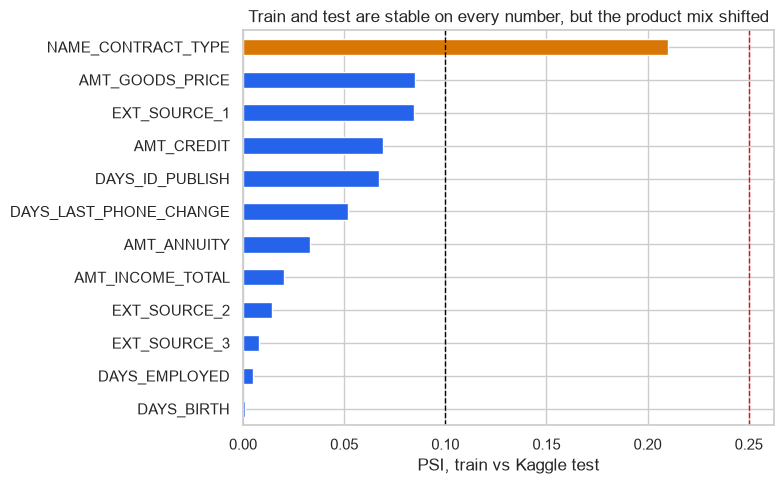

In [30]:
all_psi = pd.concat([psi_table, pd.Series({"NAME_CONTRACT_TYPE": psi_contract})]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#d97706" if v >= 0.1 else "#2563eb" for v in all_psi]
all_psi.plot.barh(ax=ax, color=colors)
ax.axvline(0.1, color="black", ls="--", lw=1)
ax.axvline(0.25, color="red", ls="--", lw=1)
ax.set_xlabel("PSI, train vs Kaggle test")
ax.set_title("Train and test are stable on every number, but the product mix shifted")
fig.tight_layout()
fig.savefig(FIGURES / "eda_psi_train_test.png", dpi=150, bbox_inches="tight")

**Finding:** no numeric variable drifts (all PSI below 0.1), but the product mix does: almost no revolving loans in the test population (PSI 0.21).
**Decision:** monitor categorical variables too, not only numbers, in the drift report. A model is validated for a portfolio: a change of product mix is a reason to re-check performance per product, even when every feature looks stable.

## 5. Key findings

1. **Finding:** `bureau` and `installments_payments` are one-to-many: median 4 external credits and 25 instalments per applicant (max 116 and 372).
   **Decision:** aggregate per `SK_ID_CURR` first, then left-join one row per applicant, and check that the row count stays at 307,511.
2. **Finding:** the two "no history" groups go in opposite directions: no Credit Bureau record means 10.12 % default (44,020 applicants, a thin file), no previous Home Credit loan means 5.98 % (15,868 new customers).
   **Decision:** keep missing aggregates as NaN (their own bin) and add the flags `HAS_BUREAU` and `HAS_INSTALMENTS`; never fill them with 0.
3. **Finding:** past behaviour is monotonic with risk: more than 20 % late instalments means 11.99 % default (vs 6.80 % for none), more than 10 % underpaid means 10.79 % (vs 7.10 %), any overdue external credit means 16.20 % (3,334 applicants).
   **Decision:** build `LATE_SHARE`, `MAX_DAYS_LATE`, `UNDERPAID_SHARE`, `N_ACTIVE` and `ANY_OVERDUE` as features; they also give the plainest reasons for a refusal.
4. **Finding:** the history is dated before the application, except `DAYS_CREDIT_UPDATE` (17 records updated after it). `DAYS_CREDIT_ENDDATE` is positive on 602,603 rows, but it is a planned end date known on the decision day; 146 end dates are more than 40 years old while the oldest credit is 8.0 years old.
   **Decision:** exclude `DAYS_CREDIT_UPDATE` from the features, keep `DAYS_CREDIT_ENDDATE`, and set impossible end dates to NaN.
5. **Finding:** numeric variables are stable between train and test (all PSI below 0.1, highest `AMT_GOODS_PRICE` at 0.085), but revolving loans fall from 9.52 % to 0.90 % of applications (PSI 0.21).
   **Decision:** monitor categorical variables as well as numeric ones in the drift report, and check performance per product.